# M1: pooled model — priors and prior predictive check

M1 is the simplest model: no brand or car-model structure, just the basic covariates.

$$
\begin{aligned}
\log(\text{price}_i) &\sim \text{Normal}(\mu_i, \sigma) \\
\mu_i &= \alpha + \beta_\text{age}\,\text{age}_i + \beta_\text{mil}\,\text{mileage}_i + \beta_\text{eng}\,\text{engineSize}_i + \beta_\text{fuel[i]} + \beta_\text{trans[i]}
\end{aligned}
$$

- Age, mileage (in units of 10k miles) and engine size are **centred** on their training-set means, so $\alpha$ is the log-price of a typical car.
- Reference levels are **Petrol** and **Manual**, so $\alpha$ is a typical petrol manual car, and the fuel and transmission coefficients are differences from it.
- On the log scale, a coefficient $\beta$ means the price changes by a factor $e^\beta$. For example, $\beta = -0.1$ is about a 10% drop.

This notebook covers only the priors. A **prior predictive check** simulates prices from the priors alone, before the model sees any prices, and checks that they are plausible.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import train_test

SEED = 2026
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

## Data

The agreed training set: 10k rows with seed 2026 (see `PROGRESS.md`). The centring means come from the training set only, so the test set can later be centred with the same values without leaking information.

In [2]:
train, test = train_test()

CENTRE = {c: train[c].mean() for c in ["age", "mileage_10k", "engineSize"]}
def add_model_columns(df):
    df = df.copy()
    for c, m in CENTRE.items():
        df[c + "_c"] = df[c] - m
    df["fuelType"] = df["fuelType"].cat.reorder_categories(["Petrol", "Diesel", "Hybrid"])
    df["transmission"] = df["transmission"].cat.reorder_categories(["Manual", "Automatic", "Semi-Auto"])
    return df

train = add_model_columns(train)
print({k: round(v, 2) for k, v in CENTRE.items()})
train[["age_c", "mileage_10k_c", "engineSize_c"]].describe().loc[["min", "max"]].round(1)

{'age': np.float64(2.89), 'mileage_10k': np.float64(2.31), 'engineSize': np.float64(1.67)}


,age_c,mileage_10k_c,engineSize_c
min,-2.9,-2.3,-0.7
max,12.1,18.9,4.9


The centred predictors range from about −3 to +12 (age, years) and from −2 to +19 (mileage, 10k miles). **These ranges matter for the priors.** A slope prior gets multiplied by the predictor value, so a wide slope prior combined with a car far from the mean gives a very large shift in log-price.

In [3]:
FORMULA = "log_price ~ age_c + mileage_10k_c + engineSize_c + fuelType + transmission"

def make_priors(b_age, b_mil, b_eng, b_cat, sigma):
    return {
        "Intercept": bmb.Prior("Normal", mu=9.5, sigma=1),
        "age_c": bmb.Prior("Normal", mu=0, sigma=b_age),
        "mileage_10k_c": bmb.Prior("Normal", mu=0, sigma=b_mil),
        "engineSize_c": bmb.Prior("Normal", mu=0, sigma=b_eng),
        "fuelType": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "transmission": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "sigma": sigma,
    }

def prior_check(priors, draws=1000):
    # center_predictors=False: we centred ourselves, so the intercept prior means exactly what we wrote.
    model = bmb.Model(FORMULA, train, priors=priors, center_predictors=False)
    model.build()
    idata = model.prior_predictive(draws=draws, random_seed=SEED)
    price = np.exp(idata.prior_predictive["log_price"].values.ravel())
    return model, idata, price

def summarise(price):
    q = np.quantile(price, [0.05, 0.5, 0.95])
    return pd.Series({
        "5%": f"£{q[0]:,.0f}", "median": f"£{q[1]:,.0f}", "95%": f"£{q[2]:,.0f}",
        "share < £500": f"{(price < 500).mean():.1%}", "share > £200k": f"{(price > 200_000).mean():.1%}",
    })

## Version 1: the agreed weakly informative priors

| Parameter | Prior |
|---|---|
| α | Normal(9.5, 1). e^9.5 ≈ £13k, and ±2 sd covers ~£2k–£100k. |
| β_age, β_mil, β_eng | Normal(0, 0.5) |
| Fuel / transmission | Normal(0, 0.5) |
| σ | Exponential(1) |

In [4]:
priors_v1 = make_priors(0.5, 0.5, 0.5, 0.5, bmb.Prior("Exponential", lam=1))
model_v1, idata_v1, price_v1 = prior_check(priors_v1)
model_v1

/home/zue/BDA-2026/.venv/lib/python3.10/site-packages/pytensor/link/c/cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Sampling: [Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


       Formula: log_price ~ age_c + mileage_10k_c + engineSize_c + fuelType + transmission
        Family: gaussian
          Link: mu = identity
  Observations: 10000
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 9.5, sigma: 1.0)
            age_c ~ Normal(mu: 0.0, sigma: 0.5)
            mileage_10k_c ~ Normal(mu: 0.0, sigma: 0.5)
            engineSize_c ~ Normal(mu: 0.0, sigma: 0.5)
            fuelType ~ Normal(mu: 0.0, sigma: 0.5)
            transmission ~ Normal(mu: 0.0, sigma: 0.5)
        
        Auxiliary parameters
            sigma ~ Exponential(lam: 1.0)

In [5]:
summarise(price_v1).to_frame("version 1")

,version 1
5%,£334
median,"£13,048"
95%,"£569,076"
share < £500,6.6%
share > £200k,9.9%


## Version 2: revised priors

Version 1 puts too much mass on impossible prices, mostly for two reasons:

1. **The slope priors are too wide for the predictor ranges.** β_age ~ Normal(0, 0.5) means a 1-sd draw (β = 0.5) combined with a 15-year-old car (centred age +12) shifts log-price by 6, which is a factor of e^6 ≈ 400. Mileage is even worse, because its range is larger.
2. **The residual sd prior is too wide.** Exponential(1) allows σ around 2–3, meaning two otherwise identical cars could differ in price by a factor of 10 or more.

The revised priors are based on what is plausible for **one unit** of each predictor, using general car-market knowledge rather than these data:

| Parameter | Version 1 | **Version 2** | Justification |
|---|---|---|---|
| β_age (per year) | Normal(0, 0.5) | **Normal(0, 0.1)** | ±2 sd = ±20% a year. Systematic gains or losses much beyond that are implausible. |
| β_mil (per 10k miles) | Normal(0, 0.5) | **Normal(0, 0.1)** | ±20% per 10k miles. |
| β_eng (per litre) | Normal(0, 0.5) | **Normal(0, 0.3)** | One litre more changes price by at most about a factor of 1.8. |
| Fuel / transmission | Normal(0, 0.5) | Normal(0, 0.5) | Unchanged. These are not multiplied by a large range. |
| σ | Exponential(1) | **HalfNormal(0.5)** | Cars with identical covariates should rarely differ by more than a factor of e (≈ 2.7). |

All of these are still centred on 0 and don't favour any direction. Revising priors after a prior predictive check is legitimate, because the check uses only the predictor values and never the observed prices.

In [6]:
priors_v2 = make_priors(0.1, 0.1, 0.3, 0.5, bmb.Prior("HalfNormal", sigma=0.5))
model_v2, idata_v2, price_v2 = prior_check(priors_v2)
pd.concat([summarise(price_v1).rename("version 1"), summarise(price_v2).rename("version 2")], axis=1)

Sampling: [Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


,version 1,version 2
5%,£334,"£1,593"
median,"£13,048","£13,085"
95%,"£569,076","£115,779"
share < £500,6.6%,0.7%
share > £200k,9.9%,2.3%


## Simulated prices

Each panel shows prices simulated from the priors, for the cars in the training set. The shaded band (£500–£200k) is the range of plausible UK used-car prices. It comes from general knowledge, not from the data.

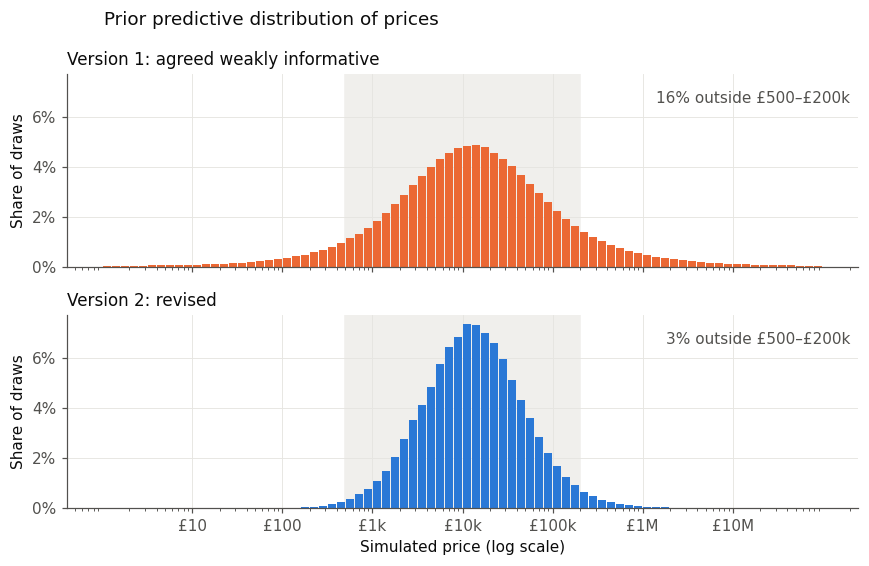

In [7]:
bins = np.logspace(0, 8, 81)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True, sharey=True)
for ax, price, colour, title in [(axes[0], price_v1, ORANGE, "Version 1: agreed weakly informative"),
                                 (axes[1], price_v2, BLUE, "Version 2: revised")]:
    ax.axvspan(500, 200_000, color="#f0efec", zorder=0)
    ax.hist(price, bins=bins, color=colour, weights=np.full(price.size, 1 / price.size), rwidth=0.85)
    ax.set_xscale("log")
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    out = (price < 500).mean() + (price > 200_000).mean()
    ax.text(0.99, 0.85, f"{out:.0%} outside £500–£200k", transform=ax.transAxes, ha="right", color=MUTED)
axes[1].set_xticks([10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000],
                   ["£10", "£100", "£1k", "£10k", "£100k", "£1M", "£10M"])
axes[1].set_xlabel("Simulated price (log scale)")
for ax in axes: ax.set_ylabel("Share of draws")
fig.suptitle("Prior predictive distribution of prices", x=0.125, ha="left", fontsize=12, color=INK)
fig.tight_layout()

## Implied depreciation curves

Each line is one draw from the prior: the predicted price of a typical petrol manual car by age, with the other covariates at their means and no residual noise. This shows what the priors say about depreciation alone.

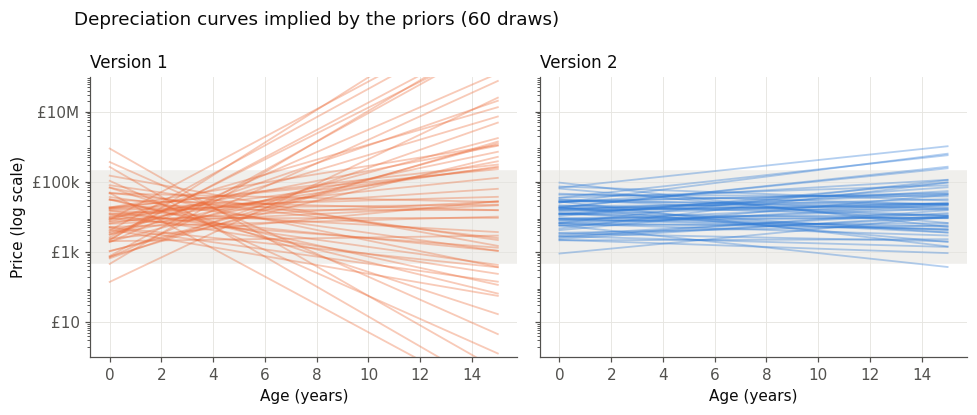

In [8]:
ages = np.arange(0, 16)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, idata, colour, title in [(axes[0], idata_v1, ORANGE, "Version 1"), (axes[1], idata_v2, BLUE, "Version 2")]:
    a = idata.prior["Intercept"].values.ravel()[:60]
    b = idata.prior["age_c"].values.ravel()[:60]
    curves = np.exp(a[:, None] + b[:, None] * (ages[None, :] - CENTRE["age"]))
    ax.axhspan(500, 200_000, color="#f0efec", zorder=0)
    ax.plot(ages, curves.T, color=colour, alpha=0.35, linewidth=1.2)
    ax.set_yscale("log")
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Age (years)")
axes[0].set_ylabel("Price (log scale)")
axes[0].set_ylim(1, 1e8)
axes[0].set_yticks([10, 1_000, 100_000, 10_000_000], ["£10", "£1k", "£100k", "£10M"])
fig.suptitle("Depreciation curves implied by the priors (60 draws)", x=0.08, ha="left", fontsize=12, color=INK)
fig.tight_layout()

## Conclusion

- **Version 1 fails** the check: it puts a large share of simulated cars outside £500–£200k. The depreciation curves show why: many have 15-year-old cars worth pennies or millions.
- **Version 2 passes.** Most simulated prices fall in the plausible range. The priors still allow cars to gain or lose value, so they don't decide the answer for the data.
- Version 2 becomes the **main (weakly informative) prior set for M1**. The vague and informative sets for the sensitivity analysis stay as listed in `PROGRESS.md`. The informative σ prior should become narrower than HalfNormal(0.5), e.g. HalfNormal(0.25), so that it differs from the main set.

**Next:** fit M1 with MCMC, then convergence diagnostics and the posterior predictive check.